# Quality comparison: RL orchestrator vs HybridLLM (MixInstruct, BARTScore)

Both systems are scored on the **same fresh held-out queries** (not in the 15k pool), using the same BARTScore and the same thresholds as the RL run.

Pipeline (every expensive step is cached to `CKPT_DIR` and resumes if interrupted):

1. Build a fresh eval set and run **all 5 models** on it once, then score with BARTScore. This is the quality table `Q[query, model]`.
2. **HybridLLM**: for each of the three pairs (large / medium / small capability gap), run the small and large model on the 10k train queries, build labels, train the router, sweep the threshold on the eval set. Llama's train outputs are generated once and shared by all pairs.
3. **RL**: load the trained orchestrator from the RL run, freeze it, and route the eval set. Sweeping an evaluation-time lambda traces an RL cost-quality curve without retraining.
4. Compare: cost-quality curves, baselines, matched-cost comparison with bootstrap CIs, ROUGE-L as a second metric.

**Run order:** first set `DRY_RUN = True` in the config cell and run everything end to end (a few minutes). Then set it to `False` and re-run.
**GPU:** shut down the RL notebook kernel first so GPU 0 has free memory. Peak use here is about 20 GB (one model is loaded at a time).

## Step 0: preflight (run this first; it stops early with the exact fix if anything is missing)

In [1]:
import sys, importlib, os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # must be set before torch is imported

REQUIRED = {"numpy": "numpy", "torch": "torch", "datasets": "datasets", "transformers": "transformers",
            "matplotlib": "matplotlib", "sentencepiece": "sentencepiece", "google.protobuf": "protobuf"}
missing = []
for mod, pip_name in REQUIRED.items():
    try:
        importlib.import_module(mod)
    except Exception:
        missing.append(pip_name)
if missing:
    raise RuntimeError("Missing packages: " + ", ".join(missing) +
        "\nInstall from a TERMINAL (pip inside Jupyter is blocked on this server), then restart the kernel:\n"
        "  " + sys.executable + " -m pip install " + " ".join(missing))

WORK = os.path.expanduser("~/hybridllm_project")
need = [WORK + "/ckpt_shared/examples.pkl", WORK + "/ckpt_shared/rl_training_state.pkl", WORK + "/outputs/rl_results.json"]
absent = [p for p in need if not os.path.exists(p)]
if absent:
    raise RuntimeError("Files from the RL run not found:\n  " + "\n  ".join(absent))

import torch
if torch.cuda.is_available():
    free_gb = torch.cuda.mem_get_info()[0] / 1e9
    print(f"free GPU memory: {free_gb:.1f} GB")
    if free_gb < 20:
        print("WARNING: less than ~20 GB free. Shut down the old RL kernel (and check nvidia-smi) before the real run.")
else:
    print("WARNING: no GPU visible to torch")
print("preflight OK: packages present, RL checkpoint files found.")

free GPU memory: 46.5 GB
preflight OK: packages present, RL checkpoint files found.


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc, math, json, random, pickle, shutil, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
                          AutoModel, BartTokenizer, BartForConditionalGeneration)
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

WORK_DIR = os.path.expanduser("~/hybridllm_project")
CKPT_DIR = os.path.join(WORK_DIR, "ckpt_shared")       # same folder as the RL notebook
OUTPUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_ckpt(name, obj):
    with open(f"{CKPT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)

def load_ckpt(name):
    path = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def load_with_retry(model_class, model_id, **kwargs):
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] load failed ({type(e).__name__}); clearing cache and re-downloading...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        target = os.path.join(cache_root, "models--" + model_id.replace("/", "--"))
        if os.path.exists(target):
            shutil.rmtree(target)
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Device: cuda
GPU: NVIDIA L40S | free GB: 46.5


## Config

In [13]:
DRY_RUN = False           # True = tiny smoke test (minutes). Set False for the real run.

PAIRS = [   # (label, small model S, large model L) -- same three pairs as the cost analysis; add more tuples if you like
    ("large_gap",  "flan-t5-small", "llama-2-7b-chat"),
    ("medium_gap", "flan-t5-large", "llama-2-7b-chat"),
    ("small_gap",  "flan-t5-xl",    "llama-2-7b-chat"),
]
EVAL_N = 1500             # fresh held-out queries scored for BOTH systems
N_TRAIN_HYB = 10000       # HybridLLM label-building queries (same 10k as the cost analysis)
MAX_NEW_TOKENS = 64       # same as the RL run
ROUTER_EPOCHS, ROUTER_LR, ROUTER_BATCH = 6, 2e-5, 16
ROUTER_ID = "microsoft/deberta-v3-small"
LAMBDAS = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]   # evaluation-time lambda sweep for RL

if DRY_RUN:
    EVAL_N, N_TRAIN_HYB, ROUTER_EPOCHS = 40, 100, 1
TAG = "dry_" if DRY_RUN else ""        # keeps dry-run caches separate from real ones

MODEL_IDS = [
    ("flan-t5-small",   "google/flan-t5-small",            False, 80e6),
    ("flan-t5-base",    "google/flan-t5-base",             False, 250e6),
    ("flan-t5-large",   "google/flan-t5-large",            False, 780e6),
    ("flan-t5-xl",      "google/flan-t5-xl",               False, 3e9),
    ("llama-2-7b-chat", "NousResearch/Llama-2-7b-chat-hf", True,  7e9),
]
GEN_BS = {"flan-t5-small": 64, "flan-t5-base": 64, "flan-t5-large": 32, "flan-t5-xl": 16, "llama-2-7b-chat": 16}
# FALLBACK: if Llama batching still errors, set "llama-2-7b-chat" to 1 (no padding at all, the same path as the RL run; slower but safe)
MODEL_NAMES = [m[0] for m in MODEL_IDS]
PARAMS = np.array([m[3] for m in MODEL_IDS])
COSTS = PARAMS / PARAMS.max()                      # same normalised cost as the RL run
N_ARMS = len(MODEL_IDS)
for _lbl, _S, _L in PAIRS:      # every pair must use only the 5 models from the RL run
    assert _S in MODEL_NAMES and _L in MODEL_NAMES and _S != _L, f"{_lbl}: {_S} / {_L} not in RL model set {MODEL_NAMES}"

# tau and lambda exactly as used in the RL run
rl_json = os.path.join(OUTPUT_DIR, "rl_results.json")
if os.path.exists(rl_json):
    _r = json.load(open(rl_json)); TAU = _r["tau_satisfaction_threshold"]; LAMBDA_COST = _r["lambda_cost"]
else:
    TAU, LAMBDA_COST = -4.5488, 0.5
print(f"pairs: {[(a, b, c) for a, b, c in PAIRS]}\ntau={TAU:.4f} | lambda(RL)={LAMBDA_COST} | DRY_RUN={DRY_RUN}")

pairs: [('large_gap', 'flan-t5-small', 'llama-2-7b-chat'), ('medium_gap', 'flan-t5-large', 'llama-2-7b-chat'), ('small_gap', 'flan-t5-xl', 'llama-2-7b-chat')]
tau=-4.5488 | lambda(RL)=0.5 | DRY_RUN=False


## Data: the 15k pool and a fresh eval set

`train_examples` (10k) are the HybridLLM label-building queries. The eval set is drawn from MixInstruct's `test` split and excludes any query in the 15k pool, so neither system has seen it.

In [14]:
train_examples, test_examples = load_ckpt("examples")        # same cached 10k / 5k as the other notebooks
pool_queries = {e["query"] for e in train_examples + test_examples}

eval_examples = load_ckpt(f"{TAG}eval_examples")
if eval_examples is None:
    try:
        ds_eval = load_dataset("llm-blender/mix-instruct", split="test")
    except Exception as e:
        print(f"test split unavailable ({type(e).__name__}); falling back to unused queries from the train split")
        ds_eval = load_dataset("llm-blender/mix-instruct", split="train")
    def build_query(ex):
        instr = (ex.get("instruction") or "").strip(); inp = (ex.get("input") or "").strip()
        return (instr + "\n" + inp).strip() if instr else inp
    order = list(range(len(ds_eval))); random.Random(SEED + 10).shuffle(order)
    eval_examples = []
    for i in order:
        ex = ds_eval[i]; q = build_query(ex); ref = (ex.get("output") or "").strip()
        if q and ref and q not in pool_queries:
            eval_examples.append({"query": q, "reference": ref})
        if len(eval_examples) == EVAL_N:
            break
    save_ckpt(f"{TAG}eval_examples", eval_examples)

hyb_train = train_examples[:N_TRAIN_HYB]
eval_q = [e["query"] for e in eval_examples]; eval_r = [e["reference"] for e in eval_examples]
hyb_q = [e["query"] for e in hyb_train];      hyb_r = [e["reference"] for e in hyb_train]
print(f"eval={len(eval_q)}  hybrid-train={len(hyb_q)}  overlap with pool: {len(set(eval_q) & pool_queries)}")

eval=1500  hybrid-train=10000  overlap with pool: 0


## Generation utilities (one model in memory at a time, batched, resumable)

Decoding is greedy with no output stripping, identical to the RL notebook, so the scores are comparable with the threshold tau.

In [15]:
def load_agent(name):
    _, model_id, is_causal, params = next(m for m in MODEL_IDS if m[0] == name)
    tok = AutoTokenizer.from_pretrained(model_id)
    if is_causal:
        tok.pad_token = tok.eos_token          # ALWAYS reuse eos for padding: a shipped/added pad token can have an id outside the embedding table
        tok.padding_side = "left"
        model = load_with_retry(AutoModelForCausalLM, model_id, torch_dtype=torch.float16).to(DEVICE)
        n_emb = model.get_input_embeddings().num_embeddings
        print(f"  [{name}] pad_token_id={tok.pad_token_id}  embedding rows={n_emb}  len(tokenizer)={len(tok)}")
        assert tok.pad_token_id < n_emb, "pad token id is outside the embedding table"
    else:
        model = load_with_retry(AutoModelForSeq2SeqLM, model_id, torch_dtype=torch.float16).to(DEVICE)
    model.eval()
    return {"name": name, "tok": tok, "model": model, "causal": is_causal}

def free_agent(entry):
    del entry["model"], entry["tok"]
    free_gpu()

OOV_REPLACED = {"n": 0}      # how many out-of-vocabulary token ids were mapped to <unk> (reported after Llama generation)

@torch.no_grad()
def generate_batch(entry, queries):
    tok, model = entry["tok"], entry["model"]
    enc = tok(queries, return_tensors="pt", truncation=True, max_length=256, padding=True).to(DEVICE)
    if entry["causal"]:
        # Some queries contain text matching an ADDED tokenizer token (id 32000), which has no row in Llama's embedding table.
        # Map any such id to <unk> instead of crashing (CUDA would hit a device-side assert).
        n_emb = model.get_input_embeddings().num_embeddings
        bad = enc["input_ids"] >= n_emb
        if bad.any():
            enc["input_ids"][bad] = tok.unk_token_id if tok.unk_token_id is not None else 0
            OOV_REPLACED["n"] += int(bad.sum())
    out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
    if entry["causal"]:
        out = out[:, enc["input_ids"].shape[1]:]
    return tok.batch_decode(out, skip_special_tokens=True)

def run_generation(name, queries, cache_name):
    cache = load_ckpt(cache_name) or {}
    pending = [i for i in range(len(queries)) if i not in cache]
    if pending:
        entry = load_agent(name); bs = GEN_BS[name]
        pending.sort(key=lambda i: -len(queries[i]))       # longest first: OOM (if any) shows up immediately
        t0 = time.time(); n_batches = math.ceil(len(pending) / bs)
        for bi in range(n_batches):
            idxs = pending[bi * bs:(bi + 1) * bs]
            for i, o in zip(idxs, generate_batch(entry, [queries[i] for i in idxs])):
                cache[i] = o
            if (bi + 1) % 20 == 0 or bi == n_batches - 1:
                save_ckpt(cache_name, cache)
                el = time.time() - t0
                print(f"  [{name}] {len(cache)}/{len(queries)} done | {el/60:.1f} min elapsed | est. remaining {el/(bi+1)*(n_batches-bi-1)/60:.1f} min"
                      + (f" | unk-replaced tokens so far: {OOV_REPLACED['n']}" if OOV_REPLACED["n"] else ""))
        free_agent(entry)
    return [cache[i] for i in range(len(queries))]

## BARTScore (same scorer as the RL run) and ROUGE-L (second metric)

In [16]:
class BARTScorer:
    def __init__(self, checkpoint="facebook/bart-large-cnn", device=DEVICE, max_length=1024):
        self.device, self.max_length = device, max_length
        self.tokenizer = BartTokenizer.from_pretrained(checkpoint)
        self.model = load_with_retry(BartForConditionalGeneration, checkpoint).to(device).eval()
        self.loss_fct = nn.NLLLoss(reduction="none", ignore_index=self.model.config.pad_token_id)
        self.lsm = nn.LogSoftmax(dim=1)

    @torch.no_grad()
    def score(self, srcs, tgts, batch_size=16):
        scores = []
        for i in range(0, len(srcs), batch_size):
            es = self.tokenizer(srcs[i:i+batch_size], max_length=self.max_length, truncation=True, padding=True, return_tensors="pt").to(self.device)
            et = self.tokenizer(tgts[i:i+batch_size], max_length=self.max_length, truncation=True, padding=True, return_tensors="pt").to(self.device)
            tgt_ids = et["input_ids"]
            out = self.model(input_ids=es["input_ids"], attention_mask=es["attention_mask"], labels=tgt_ids)
            logits = out.logits.view(-1, self.model.config.vocab_size)
            loss = self.loss_fct(self.lsm(logits), tgt_ids.view(-1)).view(tgt_ids.shape[0], -1)
            avg = loss.sum(dim=1) / (tgt_ids != self.model.config.pad_token_id).sum(dim=1)
            scores.extend((-avg).tolist())
        return scores

bart_scorer = BARTScorer()

def quality(hyps, refs):
    """q(hypothesis) = BARTScore(reference -> hypothesis), as in the RL run."""
    return bart_scorer.score(refs, hyps)

def score_cached(hyps, refs, cache_name):
    c = load_ckpt(cache_name)
    if c is None or len(c) != len(hyps):
        c = quality(hyps, refs); save_ckpt(cache_name, c)
    return np.array(c)

def lcs_len(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

def rouge_l(hyp, ref):
    h, r = hyp.lower().split()[:100], ref.lower().split()[:150]
    if not h or not r:
        return 0.0
    l = lcs_len(h, r)
    if l == 0:
        return 0.0
    p, rc = l / len(h), l / len(r)
    return 2 * p * rc / (p + rc)
print("scorer ready.")

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

scorer ready.


## Step 1: quality table on the eval set (all 5 models)

This is the reference both systems are judged against. The printed averages tell you how the five models actually rank on this metric, so check them before interpreting the router results.

In [17]:
eval_texts = {}
for name in MODEL_NAMES:
    print(f"== generating eval outputs: {name}")
    eval_texts[name] = run_generation(name, eval_q, f"{TAG}gen_eval_{name}")

Q = np.zeros((len(eval_q), N_ARMS)); RG = np.zeros_like(Q); LEN = np.zeros_like(Q)
for j, name in enumerate(MODEL_NAMES):
    Q[:, j] = score_cached(eval_texts[name], eval_r, f"{TAG}bart_eval_{name}")
    RG[:, j] = [rouge_l(h, r) for h, r in zip(eval_texts[name], eval_r)]
    LEN[:, j] = [len(h.split()) for h in eval_texts[name]]

print(f"\n{'model':>16} {'cost':>6} {'BARTScore':>10} {'pass@tau':>9} {'ROUGE-L':>8} {'avg words':>10}")
for j, name in enumerate(MODEL_NAMES):
    print(f"{name:>16} {COSTS[j]:6.3f} {Q[:, j].mean():10.3f} {100*(Q[:, j] >= TAU).mean():8.1f}% {RG[:, j].mean():8.3f} {LEN[:, j].mean():10.1f}")

== generating eval outputs: flan-t5-small
== generating eval outputs: flan-t5-base
== generating eval outputs: flan-t5-large
== generating eval outputs: flan-t5-xl
== generating eval outputs: llama-2-7b-chat


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

  [llama-2-7b-chat] pad_token_id=2  embedding rows=32000  len(tokenizer)=32001
  [llama-2-7b-chat] 320/1500 done | 0.6 min elapsed | est. remaining 2.4 min | unk-replaced tokens so far: 1
  [llama-2-7b-chat] 640/1500 done | 1.2 min elapsed | est. remaining 1.6 min | unk-replaced tokens so far: 1
  [llama-2-7b-chat] 960/1500 done | 1.7 min elapsed | est. remaining 1.0 min | unk-replaced tokens so far: 1
  [llama-2-7b-chat] 1280/1500 done | 2.3 min elapsed | est. remaining 0.4 min | unk-replaced tokens so far: 1
  [llama-2-7b-chat] 1500/1500 done | 2.7 min elapsed | est. remaining 0.0 min | unk-replaced tokens so far: 1

           model   cost  BARTScore  pass@tau  ROUGE-L  avg words
   flan-t5-small  0.011     -4.720     53.1%    0.085        7.9
    flan-t5-base  0.036     -4.750     50.1%    0.086        8.1
   flan-t5-large  0.111     -4.727     50.0%    0.086        7.2
      flan-t5-xl  0.429     -4.344     57.8%    0.098        8.6
 llama-2-7b-chat  1.000     -3.424     90.9%    

## Step 2: HybridLLM on all three pairs

For each pair, both models answer every training query and each answer is BARTScored. Let `H = q(small) - q(large)`.

- **r_det**: label 1 if `H >= 0` (small is at least as good).
- **r_trans**: label 1 if `H >= -t`, with `t` chosen so that about half the labels are positive. This is a simplified version of the paper's transformed label, which exists for the same reason: with a big capability gap, r_det labels are almost all 0. If your earlier notebook implements the paper's exact `t` selection, swap it in here.

Then a DeBERTa-v3-small router (binary head: P(small is good enough)) is trained once per pair and label type, and predicts on the eval set. Outputs already generated are reused from the cache.

In [18]:
hyb_tok = AutoTokenizer.from_pretrained(ROUTER_ID)

def train_router(labels, cache_key):
    cached = load_ckpt(f"{TAG}router_p_eval_{cache_key}")
    if cached is not None:
        return np.array(cached)
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    head = nn.Linear(backbone.config.hidden_size, 1).to(DEVICE)
    opt = torch.optim.AdamW(list(backbone.parameters()) + list(head.parameters()), lr=ROUTER_LR)
    y = torch.tensor(labels, dtype=torch.float32); n = len(hyb_q)
    for ep in range(ROUTER_EPOCHS):
        backbone.train(); perm = np.random.permutation(n); tot = 0.0
        for b in range(0, n, ROUTER_BATCH):
            ids = perm[b:b + ROUTER_BATCH]
            enc = hyb_tok([hyb_q[i] for i in ids], return_tensors="pt", truncation=True, max_length=128, padding=True).to(DEVICE)
            logit = head(backbone(**enc).last_hidden_state[:, 0]).squeeze(-1)
            loss = F.binary_cross_entropy_with_logits(logit, y[torch.as_tensor(ids)].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(ids)
        print(f"  [{cache_key}] epoch {ep+1}/{ROUTER_EPOCHS}  train BCE = {tot/n:.4f}")
    backbone.eval(); p = []
    with torch.no_grad():
        for b in range(0, len(eval_q), 32):
            enc = hyb_tok(eval_q[b:b+32], return_tensors="pt", truncation=True, max_length=128, padding=True).to(DEVICE)
            p.extend(torch.sigmoid(head(backbone(**enc).last_hidden_state[:, 0]).squeeze(-1)).tolist())
    save_ckpt(f"{TAG}router_p_eval_{cache_key}", p)
    del backbone, head, opt; free_gpu()
    return np.array(p)

pair_data = {}
for label, S, L in PAIRS:
    print(f"\n######## {label}: S={S}  L={L}  ({len(hyb_q)} train queries)")
    outS = run_generation(S, hyb_q, f"{TAG}gen_hyb_{S}")
    outL = run_generation(L, hyb_q, f"{TAG}gen_hyb_{L}")      # generated once, reused by every pair that shares L
    qS = score_cached(outS, hyb_r, f"{TAG}bart_hyb_{S}")
    qL = score_cached(outL, hyb_r, f"{TAG}bart_hyb_{L}")
    H = qS - qL
    t_shift = max(0.0, float(-np.median(H)))
    lab_det = (H >= 0).astype(np.float32); lab_trans = (H >= -t_shift).astype(np.float32)
    print(f"mean q(S)={qS.mean():.3f}  mean q(L)={qL.mean():.3f} | r_det positive rate {lab_det.mean():.3f} | r_trans positive rate {lab_trans.mean():.3f} (t={t_shift:.3f})")
    key = S if L == "llama-2-7b-chat" else f"{S}__{L}"
    pair_data[label] = {"S": S, "L": L, "S_IDX": MODEL_NAMES.index(S), "L_IDX": MODEL_NAMES.index(L),
                        "label_stats": {"mean_qS": float(qS.mean()), "mean_qL": float(qL.mean()),
                                        "pos_rate_det": float(lab_det.mean()), "pos_rate_trans": float(lab_trans.mean()), "t": t_shift},
                        "p": {"r_det": train_router(lab_det, f"{key}_det"), "r_trans": train_router(lab_trans, f"{key}_trans")}}
print("\nall routers ready:", list(pair_data))


######## large_gap: S=flan-t5-small  L=llama-2-7b-chat  (10000 train queries)


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


  [flan-t5-small] 1280/10000 done | 0.2 min elapsed | est. remaining 1.5 min | unk-replaced tokens so far: 1
  [flan-t5-small] 2560/10000 done | 0.4 min elapsed | est. remaining 1.2 min | unk-replaced tokens so far: 1
  [flan-t5-small] 3840/10000 done | 0.6 min elapsed | est. remaining 1.0 min | unk-replaced tokens so far: 1
  [flan-t5-small] 5120/10000 done | 0.8 min elapsed | est. remaining 0.8 min | unk-replaced tokens so far: 1
  [flan-t5-small] 6400/10000 done | 1.0 min elapsed | est. remaining 0.6 min | unk-replaced tokens so far: 1
  [flan-t5-small] 7680/10000 done | 1.2 min elapsed | est. remaining 0.4 min | unk-replaced tokens so far: 1
  [flan-t5-small] 8960/10000 done | 1.4 min elapsed | est. remaining 0.2 min | unk-replaced tokens so far: 1
  [flan-t5-small] 10000/10000 done | 1.6 min elapsed | est. remaining 0.0 min | unk-replaced tokens so far: 1


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [flan-t5-xl_det] epoch 1/6  train BCE = 0.5496
  [flan-t5-xl_det] epoch 2/6  train BCE = 0.4626
  [flan-t5-xl_det] epoch 3/6  train BCE = 0.3767
  [flan-t5-xl_det] epoch 4/6  train BCE = 0.2679
  [flan-t5-xl_det] epoch 5/6  train BCE = 0.1789
  [flan-t5-xl_det] epoch 6/6  train BCE = 0.1210


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [flan-t5-xl_trans] epoch 1/6  train BCE = 0.5390
  [flan-t5-xl_trans] epoch 2/6  train BCE = 0.4560
  [flan-t5-xl_trans] epoch 3/6  train BCE = 0.3863
  [flan-t5-xl_trans] epoch 4/6  train BCE = 0.2937
  [flan-t5-xl_trans] epoch 5/6  train BCE = 0.2012
  [flan-t5-xl_trans] epoch 6/6  train BCE = 0.1321

all routers ready: ['large_gap', 'medium_gap', 'small_gap']


## Step 3: the RL orchestrator, frozen

Loads the trained policy saved by the RL notebook (`rl_training_state`). The head was trained to predict `reward = satisfaction - lambda*cost`, so the estimated satisfaction is `value + lambda*cost`. Re-choosing with a different evaluation-time lambda `lam'` is `argmax(value + lambda*cost - lam'*cost)`; `lam' = 0.5` reproduces the trained policy exactly.

In [19]:
class OrchestratorHead(nn.Module):
    def __init__(self, hidden_size, n_agents):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(hidden_size, 128), nn.ReLU(), nn.Linear(128, n_agents))
    def forward(self, state):
        return self.net(state)

st = load_ckpt("rl_training_state")
assert st is not None, "rl_training_state checkpoint not found in CKPT_DIR (run the RL notebook first)"
print("RL checkpoint step:", st["step"])
rl_backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
rl_backbone.load_state_dict(st["backbone_state"]); rl_backbone.eval()
rl_head = OrchestratorHead(rl_backbone.config.hidden_size, N_ARMS).to(DEVICE)
rl_head.load_state_dict(st["head_state"]); rl_head.eval()

vals = []
with torch.no_grad():
    for b in range(0, len(eval_q), 32):
        enc = hyb_tok(eval_q[b:b+32], return_tensors="pt", truncation=True, max_length=128, padding=True).to(DEVICE)
        vals.append(rl_head(rl_backbone(**enc).last_hidden_state[:, 0]).cpu().numpy())
rl_values = np.concatenate(vals)
del rl_backbone, rl_head; free_gpu()

est_sat = rl_values + LAMBDA_COST * COSTS[None, :]
def rl_choice(lam): return np.argmax(est_sat - lam * COSTS[None, :], axis=1)
print("RL greedy choice distribution on eval set:", Counter(np.array(MODEL_NAMES)[rl_choice(LAMBDA_COST)]))

RL checkpoint step: 15000


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RL greedy choice distribution on eval set: Counter({np.str_('llama-2-7b-chat'): 961, np.str_('flan-t5-large'): 429, np.str_('flan-t5-small'): 88, np.str_('flan-t5-base'): 22})


## Step 4: evaluate every method on the same eval set

In [20]:
ar = np.arange(len(eval_q)); LLAMA_IDX = MODEL_NAMES.index("llama-2-7b-chat")
def evaluate(choice):
    choice = np.asarray(choice)
    q = Q[ar, choice]
    return {"bart": float(q.mean()), "pass": float((q >= TAU).mean()), "rouge": float(RG[ar, choice].mean()),
            "cost": float(COSTS[choice].mean()), "share_llama": float((choice == LLAMA_IDX).mean()),
            "utility": float((np.where(q >= TAU, 1, -1) - LAMBDA_COST * COSTS[choice]).mean())}

# HybridLLM: route to small if P(small ok) >= theta
for label, d in pair_data.items():
    d["curves"] = {}
    for lt, p in d["p"].items():
        thetas = np.unique(np.concatenate([[0.0], np.quantile(p, np.linspace(0, 1, 41)), [1.0001]]))
        d["curves"][lt] = [dict(evaluate(np.where(p >= th, d["S_IDX"], d["L_IDX"])), theta=float(th)) for th in thetas]

# RL: evaluation-time lambda sweep (same curve is drawn in every pair's panel)
rl_curve = [dict(evaluate(rl_choice(l)), lam=l) for l in LAMBDAS]
rl_point = evaluate(rl_choice(LAMBDA_COST))

baselines = {f"always {n}": evaluate([j] * len(eval_q)) for j, n in enumerate(MODEL_NAMES)}
baselines["random (uniform over 5)"] = evaluate(np.random.RandomState(1).randint(0, N_ARMS, len(eval_q)))
baselines["oracle: cheapest model passing tau"] = evaluate([int(np.argmax(r >= TAU)) if (r >= TAU).any() else int(np.argmax(r)) for r in Q])
baselines["oracle: best-quality model"] = evaluate(np.argmax(Q, axis=1))

print(f"{'method':>38} {'cost':>6} {'BARTScore':>10} {'pass':>6} {'ROUGE-L':>8} {'utility':>8}")
rows = dict(baselines); rows["RL (trained, lambda=0.5)"] = rl_point
for k, v in rows.items():
    print(f"{k:>38} {v['cost']:6.3f} {v['bart']:10.3f} {100*v['pass']:5.1f}% {v['rouge']:8.3f} {v['utility']:+8.3f}")

                                method   cost  BARTScore   pass  ROUGE-L  utility
                  always flan-t5-small  0.011     -4.720  53.1%    0.085   +0.056
                   always flan-t5-base  0.036     -4.750  50.1%    0.086   -0.015
                  always flan-t5-large  0.111     -4.727  50.0%    0.086   -0.056
                     always flan-t5-xl  0.429     -4.344  57.8%    0.098   -0.058
                always llama-2-7b-chat  1.000     -3.424  90.9%    0.223   +0.319
               random (uniform over 5)  0.317     -4.378  61.3%    0.117   +0.068
    oracle: cheapest model passing tau  0.293     -3.094  96.9%    0.159   +0.792
            oracle: best-quality model  0.510     -2.637  96.9%    0.196   +0.684
              RL (trained, lambda=0.5)  0.674     -3.329  88.8%    0.202   +0.439


## Step 5: matched-cost comparison with confidence intervals

Comparing a single RL point with a HybridLLM curve is only fair at equal cost. For each pair and label type we (a) interpolate the HybridLLM curve at the RL cost and (b) take its operating point nearest in cost and compute the paired bootstrap 95% CI of the per-query BARTScore difference (RL minus HybridLLM).

In [21]:
def paired_boot(a, b, n=2000, seed=0):
    d = np.asarray(a) - np.asarray(b)
    idx = np.random.RandomState(seed).randint(0, len(d), (n, len(d)))
    m = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

rl_ch = rl_choice(LAMBDA_COST); q_rl = Q[ar, rl_ch]
print(f"RL point: cost={rl_point['cost']:.3f}  BARTScore={rl_point['bart']:.3f}  pass={100*rl_point['pass']:.1f}%\n")
summary_rows = []
for label, d in pair_data.items():
    d["matched_cost"] = {}
    for lt, p in d["p"].items():
        pts = sorted(d["curves"][lt], key=lambda x: x["cost"])
        interp_bart = float(np.interp(rl_point["cost"], [x["cost"] for x in pts], [x["bart"] for x in pts]))
        interp_pass = float(np.interp(rl_point["cost"], [x["cost"] for x in pts], [x["pass"] for x in pts]))
        near = min(pts, key=lambda x: abs(x["cost"] - rl_point["cost"]))
        q_h = Q[ar, np.where(p >= near["theta"], d["S_IDX"], d["L_IDX"])]
        diff, lo, hi = paired_boot(q_rl, q_h)
        verdict = "RL better" if lo > 0 else ("HybridLLM better" if hi < 0 else "no significant difference")
        d["matched_cost"][lt] = {"hybrid_bart_at_rl_cost": interp_bart, "hybrid_pass_at_rl_cost": interp_pass,
                                 "nearest_cost": near["cost"], "diff_bart": diff, "ci95": [lo, hi], "verdict": verdict}
        summary_rows.append((label, f"{d['S']} + {d['L']}", lt, near["cost"], interp_bart, diff, lo, hi, verdict))

print(f"{'pair':>11} {'models':>30} {'label':>8} {'hyb cost':>9} {'hyb BART@RLcost':>16} {'RL-Hyb':>8} {'95% CI':>18}  verdict")
for r in summary_rows:
    print(f"{r[0]:>11} {r[1]:>30} {r[2]:>8} {r[3]:9.3f} {r[4]:16.3f} {r[5]:+8.3f} [{r[6]:+.3f}, {r[7]:+.3f}]  {r[8]}")

RL point: cost=0.674  BARTScore=-3.329  pass=88.8%

       pair                         models    label  hyb cost  hyb BART@RLcost   RL-Hyb             95% CI  verdict
  large_gap flan-t5-small + llama-2-7b-chat    r_det     0.678           -3.380   +0.052 [-0.010, +0.115]  no significant difference
  large_gap flan-t5-small + llama-2-7b-chat  r_trans     0.678           -3.354   +0.023 [-0.032, +0.080]  no significant difference
 medium_gap flan-t5-large + llama-2-7b-chat    r_det     0.666           -3.248   -0.080 [-0.122, -0.038]  HybridLLM better
 medium_gap flan-t5-large + llama-2-7b-chat  r_trans     0.666           -3.316   -0.012 [-0.059, +0.036]  no significant difference
  small_gap   flan-t5-xl + llama-2-7b-chat    r_det     0.672           -3.338   +0.015 [-0.055, +0.080]  no significant difference
  small_gap   flan-t5-xl + llama-2-7b-chat  r_trans     0.672           -3.329   +0.002 [-0.065, +0.068]  no significant difference


## Plots and export

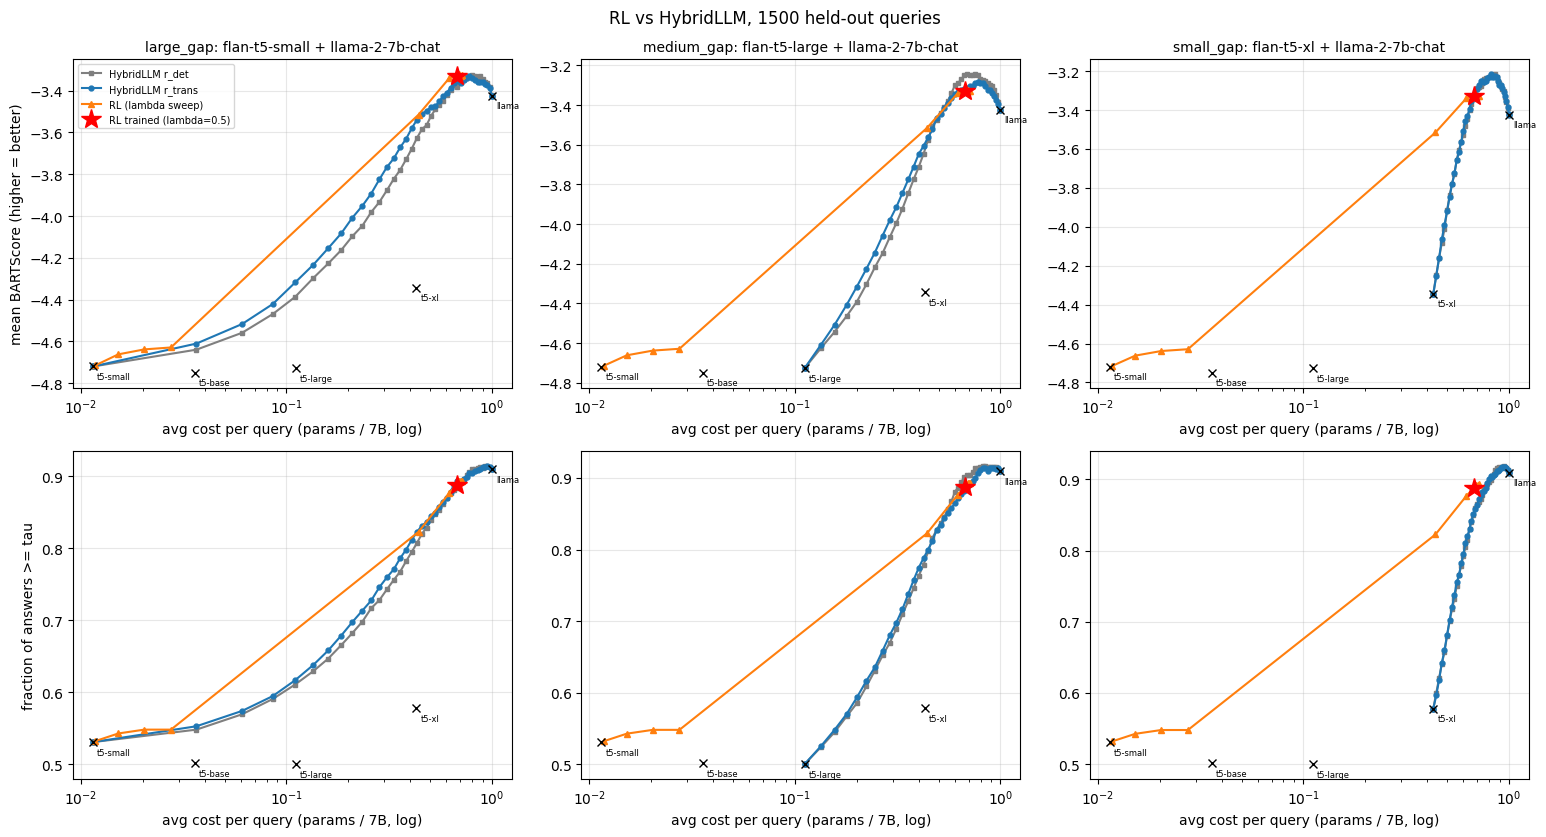

saved /home/bhavana.ravi/hybridllm_project/outputs/quality_comparison.json


In [22]:
fig, axes = plt.subplots(2, len(pair_data), figsize=(5.2 * len(pair_data), 8.5), squeeze=False)
styles = {"r_det": ("tab:gray", "s-"), "r_trans": ("tab:blue", "o-")}
for ci, (label, d) in enumerate(pair_data.items()):
    for ri, (key, ylabel) in enumerate([("bart", "mean BARTScore (higher = better)"), ("pass", "fraction of answers >= tau")]):
        ai = axes[ri][ci]
        for lt, (c, fmt) in styles.items():
            pts = sorted(d["curves"][lt], key=lambda x: x["cost"])
            ai.plot([x["cost"] for x in pts], [x[key] for x in pts], fmt, color=c, ms=3.5, label=f"HybridLLM {lt}")
        pts = sorted(rl_curve, key=lambda x: x["cost"])
        ai.plot([x["cost"] for x in pts], [x[key] for x in pts], "^-", color="tab:orange", ms=4, label="RL (lambda sweep)")
        ai.plot(rl_point["cost"], rl_point[key], "*", color="red", ms=15, label="RL trained (lambda=0.5)", zorder=5)
        for j, n in enumerate(MODEL_NAMES):
            ai.plot(COSTS[j], baselines[f"always {n}"][key], "kx", ms=6)
            ai.annotate(n.replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (COSTS[j], baselines[f"always {n}"][key]),
                        textcoords="offset points", xytext=(3, -9), fontsize=6)
        ai.set_xscale("log"); ai.grid(alpha=0.3); ai.set_xlabel("avg cost per query (params / 7B, log)")
        if ci == 0: ai.set_ylabel(ylabel)
        if ri == 0: ai.set_title(f"{label}: {d['S']} + {d['L']}", fontsize=10)
axes[0][0].legend(fontsize=7)
plt.suptitle(f"RL vs HybridLLM, {len(eval_q)} held-out queries"); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, f"{TAG}quality_vs_cost.png"), dpi=150); plt.show()

out = {"n_eval": len(eval_q), "n_train_hybrid": len(hyb_q), "tau": TAU, "lambda_rl": LAMBDA_COST,
       "per_model": {n: {"cost": float(COSTS[j]), "bart": float(Q[:, j].mean()), "pass": float((Q[:, j] >= TAU).mean()),
                         "rouge": float(RG[:, j].mean()), "avg_words": float(LEN[:, j].mean())} for j, n in enumerate(MODEL_NAMES)},
       "baselines": baselines, "rl_point": rl_point, "rl_curve": rl_curve,
       "pairs": {label: {"small": d["S"], "large": d["L"], "label_stats": d["label_stats"], "curves": d["curves"],
                         "matched_cost": d["matched_cost"]} for label, d in pair_data.items()}}
with open(os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"), "w") as f:
    json.dump(out, f, indent=2)
print("saved", os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"))

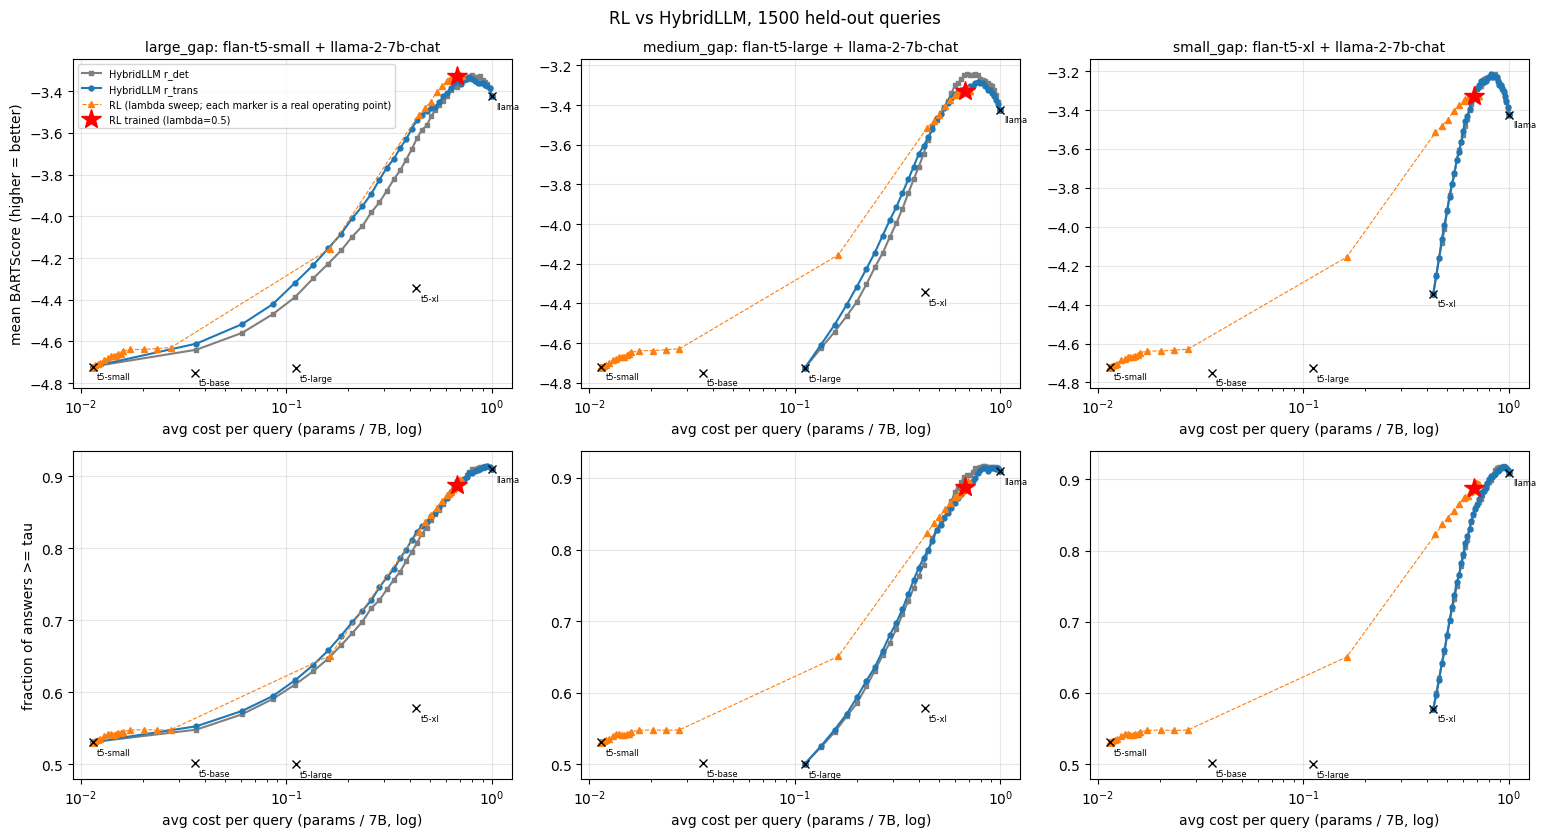

saved /home/bhavana.ravi/hybridllm_project/outputs/quality_comparison.json


In [23]:
LAMBDAS = sorted(set(np.round(np.concatenate([np.linspace(0, 1, 26), np.linspace(1.25, 8, 28), [0.5]]), 3).tolist()))   # dense evaluation-time lambda sweep for RL
rl_curve = [dict(evaluate(rl_choice(l)), lam=l) for l in LAMBDAS]      # dense RL sweep (real operating points)

fig, axes = plt.subplots(2, len(pair_data), figsize=(5.2 * len(pair_data), 8.5), squeeze=False)
styles = {"r_det": ("tab:gray", "s-"), "r_trans": ("tab:blue", "o-")}
for ci, (label, d) in enumerate(pair_data.items()):
    for ri, (key, ylabel) in enumerate([("bart", "mean BARTScore (higher = better)"), ("pass", "fraction of answers >= tau")]):
        ai = axes[ri][ci]
        for lt, (c, fmt) in styles.items():
            pts = sorted(d["curves"][lt], key=lambda x: x["cost"])
            ai.plot([x["cost"] for x in pts], [x[key] for x in pts], fmt, color=c, ms=3.5, label=f"HybridLLM {lt}")
        pts = sorted(rl_curve, key=lambda x: x["cost"])
        ai.plot([x["cost"] for x in pts], [x[key] for x in pts], "^--", color="tab:orange", lw=0.8, ms=4, label="RL (lambda sweep; each marker is a real operating point)")
        ai.plot(rl_point["cost"], rl_point[key], "*", color="red", ms=15, label="RL trained (lambda=0.5)", zorder=5)
        for j, n in enumerate(MODEL_NAMES):
            ai.plot(COSTS[j], baselines[f"always {n}"][key], "kx", ms=6)
            ai.annotate(n.replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (COSTS[j], baselines[f"always {n}"][key]),
                        textcoords="offset points", xytext=(3, -9), fontsize=6)
        ai.set_xscale("log"); ai.grid(alpha=0.3); ai.set_xlabel("avg cost per query (params / 7B, log)")
        if ci == 0: ai.set_ylabel(ylabel)
        if ri == 0: ai.set_title(f"{label}: {d['S']} + {d['L']}", fontsize=10)
axes[0][0].legend(fontsize=7)
plt.suptitle(f"RL vs HybridLLM, {len(eval_q)} held-out queries"); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, f"{TAG}quality_vs_cost.png"), dpi=150); plt.show()

out = {"n_eval": len(eval_q), "n_train_hybrid": len(hyb_q), "tau": TAU, "lambda_rl": LAMBDA_COST,
       "per_model": {n: {"cost": float(COSTS[j]), "bart": float(Q[:, j].mean()), "pass": float((Q[:, j] >= TAU).mean()),
                         "rouge": float(RG[:, j].mean()), "avg_words": float(LEN[:, j].mean())} for j, n in enumerate(MODEL_NAMES)},
       "baselines": baselines, "rl_point": rl_point, "rl_curve": rl_curve,
       "pairs": {label: {"small": d["S"], "large": d["L"], "label_stats": d["label_stats"], "curves": d["curves"],
                         "matched_cost": d["matched_cost"]} for label, d in pair_data.items()}}
with open(os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"), "w") as f:
    json.dump(out, f, indent=2)
print("saved", os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"))

In [25]:
import csv
def save_csv(name, header, rows):
    with open(os.path.join(OUTPUT_DIR, f"{TAG}{name}.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)

LB = MODEL_NAMES.index("llama-2-7b-chat")
def hybrid_choice_at_rl_cost(d, lt):
    pts = d["curves"][lt]; near = min(pts, key=lambda x: abs(x["cost"] - rl_point["cost"]))
    return np.where(d["p"][lt] >= near["theta"], d["S_IDX"], d["L_IDX"]), near

# ---- Table A: the five models ----
print("TABLE A: the five models on the eval set")
hdr = ["model", "cost", "BARTScore", "pass@tau", "ROUGE-L", "avg_words"]
rowsA = [[n, round(float(COSTS[j]), 3), round(float(Q[:, j].mean()), 3), round(float((Q[:, j] >= TAU).mean()), 3),
          round(float(RG[:, j].mean()), 3), round(float(LEN[:, j].mean()), 1)] for j, n in enumerate(MODEL_NAMES)]
for r in [hdr] + rowsA: print("  " + " | ".join(f"{str(x):>16}" for x in r))
save_csv("tableA_models", hdr, rowsA)

# ---- Table B: RL vs HybridLLM at (nearly) the same serving cost ----
print("\nTABLE B: matched serving cost (HybridLLM operating point nearest to RL's cost)")
hdr = ["method", "cost", "BARTScore", "pass@tau", "ROUGE-L", "share_to_llama", "utility"]
rowsB = [["Always Llama", *[round(baselines["always llama-2-7b-chat"][k], 3) for k in ["cost", "bart", "pass", "rouge", "share_llama", "utility"]]],
         ["RL (trained)", *[round(rl_point[k], 3) for k in ["cost", "bart", "pass", "rouge", "share_llama", "utility"]]]]
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, near = hybrid_choice_at_rl_cost(d, lt); e = evaluate(ch)
        rowsB.append([f"Hybrid {label} {lt}", *[round(e[k], 3) for k in ["cost", "bart", "pass", "rouge", "share_llama", "utility"]]])
for r in [hdr] + rowsB: print("  " + " | ".join(f"{str(x):>22}" for x in r))
save_csv("tableB_matched_cost", hdr, rowsB)

# ---- Table C: per-query head-to-head (pass / fail at tau) ----
print("\nTABLE C: per-query head-to-head, % of eval queries (RL vs HybridLLM at matched cost)")
hdr = ["pair", "label", "both pass", "only RL passes", "only Hybrid passes", "both fail", "RL answer better by >0.5 BART", "Hybrid better by >0.5 BART"]
rowsC = []
pass_rl = Q[ar, rl_choice(LAMBDA_COST)] >= TAU; q_rl_ = Q[ar, rl_choice(LAMBDA_COST)]
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, near = hybrid_choice_at_rl_cost(d, lt); ph = Q[ar, ch] >= TAU; qh = Q[ar, ch]
        rowsC.append([label, lt, *[round(100 * float(x.mean()), 1) for x in [pass_rl & ph, pass_rl & ~ph, ~pass_rl & ph, ~pass_rl & ~ph, q_rl_ - qh > 0.5, qh - q_rl_ > 0.5]]])
for r in [hdr] + rowsC: print("  " + " | ".join(f"{str(x):>14}" for x in r))
save_csv("tableC_head_to_head", hdr, rowsC)

# ---- Table D: where each router sends queries ----
print("\nTABLE D: routing behaviour (% of eval queries sent to each model)")
hdr = ["router"] + MODEL_NAMES
rowsD = [["RL (trained)"] + [round(100 * float((rl_choice(LAMBDA_COST) == j).mean()), 1) for j in range(N_ARMS)]]
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, _ = hybrid_choice_at_rl_cost(d, lt)
        rowsD.append([f"Hybrid {label} {lt}"] + [round(100 * float((ch == j).mean()), 1) for j in range(N_ARMS)])
orc = np.array([int(np.argmax(r >= TAU)) if (r >= TAU).any() else int(np.argmax(r)) for r in Q])
rowsD.append(["Oracle (cheapest passing)"] + [round(100 * float((orc == j).mean()), 1) for j in range(N_ARMS)])
for r in [hdr] + rowsD: print("  " + " | ".join(f"{str(x):>22}" for x in r))
save_csv("tableD_routing", hdr, rowsD)

# ---- Table E: total cost when HybridLLM is run at the matched operating point ----
print("\nTABLE E: total cost (raw params x calls), RL online on 15k vs HybridLLM 10k label-building + 5k served at the matched cost")
try:
    Rj = json.load(open(os.path.join(OUTPUT_DIR, "rl_results.json")))
    rl_total_raw = float(sum(PARAMS[MODEL_NAMES.index(a)] for a in Rj["action_log"]))
except Exception as e:
    rl_total_raw = float("nan"); print("  (could not recompute RL total from rl_results.json:", e, ")")
hdr = ["pair", "label_building_T", "serving_5k_T", "hybrid_total_T", "RL_total_T", "hybrid/RL"]
rowsE = []
for label, d in pair_data.items():
    lb = 10000 * (PARAMS[d["S_IDX"]] + PARAMS[d["L_IDX"]])
    _, near = hybrid_choice_at_rl_cost(d, "r_trans"); serve = 5000 * near["cost"] * PARAMS.max()
    rowsE.append([label, round(lb / 1e12, 1), round(serve / 1e12, 1), round((lb + serve) / 1e12, 1), round(rl_total_raw / 1e12, 1), round((lb + serve) / rl_total_raw, 2)])
for r in [hdr] + rowsE: print("  " + " | ".join(f"{str(x):>16}" for x in r))
save_csv("tableE_total_cost", hdr, rowsE)

# ---- Table F: example answers for a qualitative slide ----
print("\nTABLE F: examples where RL chose a cheaper model (saved to CSV; first 3 shown)")
ch_rl = rl_choice(LAMBDA_COST)
cands = [i for i in range(len(eval_q)) if ch_rl[i] != LB and Q[i, ch_rl[i]] >= TAU and Q[i, ch_rl[i]] > Q[i, LB] + 0.5]
fails = [i for i in range(len(eval_q)) if ch_rl[i] != LB and Q[i, ch_rl[i]] < TAU and Q[i, LB] >= TAU]
rowsF = []
for kind, ids in [("cheap model good (beats Llama)", cands[:4]), ("cheap model failed (Llama would pass)", fails[:3])]:
    for i in ids:
        m = MODEL_NAMES[ch_rl[i]]
        rowsF.append([kind, eval_q[i][:160].replace("\n", " "), m, eval_texts[m][i][:200].replace("\n", " "), round(float(Q[i, ch_rl[i]]), 2),
                      eval_texts["llama-2-7b-chat"][i][:200].replace("\n", " "), round(float(Q[i, LB]), 2), eval_r[i][:200].replace("\n", " ")])
save_csv("tableF_examples", ["case", "query", "RL_model", "RL_answer", "RL_BART", "llama_answer", "llama_BART", "reference"], rowsF)
for r in rowsF[:3]: print("  ", r[0], "|", r[1][:80], "|", r[2], "|", r[4], "vs llama", r[6])
print(f"\n(candidate counts: {len(cands)} good-cheap cases, {len(fails)} failed-cheap cases)")

TABLE A: the five models on the eval set
             model |             cost |        BARTScore |         pass@tau |          ROUGE-L |        avg_words
     flan-t5-small |            0.011 |            -4.72 |            0.531 |            0.085 |              7.9
      flan-t5-base |            0.036 |            -4.75 |            0.501 |            0.086 |              8.1
     flan-t5-large |            0.111 |           -4.727 |              0.5 |            0.086 |              7.2
        flan-t5-xl |            0.429 |           -4.344 |            0.578 |            0.098 |              8.6
   llama-2-7b-chat |              1.0 |           -3.424 |            0.909 |            0.223 |             40.5

TABLE B: matched serving cost (HybridLLM operating point nearest to RL's cost)
                  method |                   cost |              BARTScore |               pass@tau |                ROUGE-L |         share_to_llama |                utility
            Always L